## Importer les bibliothèque

In [ ]:

# import pandas as pd
import kagglehub
from pathlib import Path
import numpy as np
from PIL import Image
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array


## Charger le dataset

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


## Explorer la structure

In [3]:


train_dir =  path / "chest_xray" / "chest_xray" / "train"

val_dir =  path / "chest_xray" / "chest_xray" / "val"

test_dir =  path / "chest_xray" / "chest_xray" / "test"


train_classes_paths = [train_dir / "NORMAL", train_dir / "PNEUMONIA"]
val_classes_paths = [val_dir / "NORMAL", val_dir / "PNEUMONIA"]
test_classes_paths = [test_dir / "NORMAL", test_dir / "PNEUMONIA"]




## Vérifier le nombre d'images & la répartition des images

In [4]:
  
allowed_ext = (".jpeg", ".png", ".jpg")
def get_images(images_dir: list, type_index):
    return [
        i for i in images_dir[type_index].rglob("*")
        if i.name.endswith(allowed_ext)
    ]

In [5]:
def charts(count: dict):
    classes = ("NORMAL", "PNEUMONIA")
    fig, axes = plt.subplots(1, 3,  figsize=(12, 5),)
    
    for key, value in count.items():
        i = list(count.keys()).index(key)
        axes[i].bar(classes, value)
        axes[i].set_title(key)
        axes[i].set_xlabel("classes")
        axes[i].set_ylabel(f"{key} count")
    
    plt.tight_layout()
    plt.show()
    

In [6]:

# TRAIN


train_image = {
    "normal": get_images(train_classes_paths, 0),
    "pneumonia": get_images(train_classes_paths, 1)
}

val_image = {
    "normal": get_images(val_classes_paths, 0),
    "pneumonia": get_images(val_classes_paths, 1)
}

test_image = {
    "normal": get_images(test_classes_paths, 0),
    "pneumonia": get_images(test_classes_paths, 1)
}


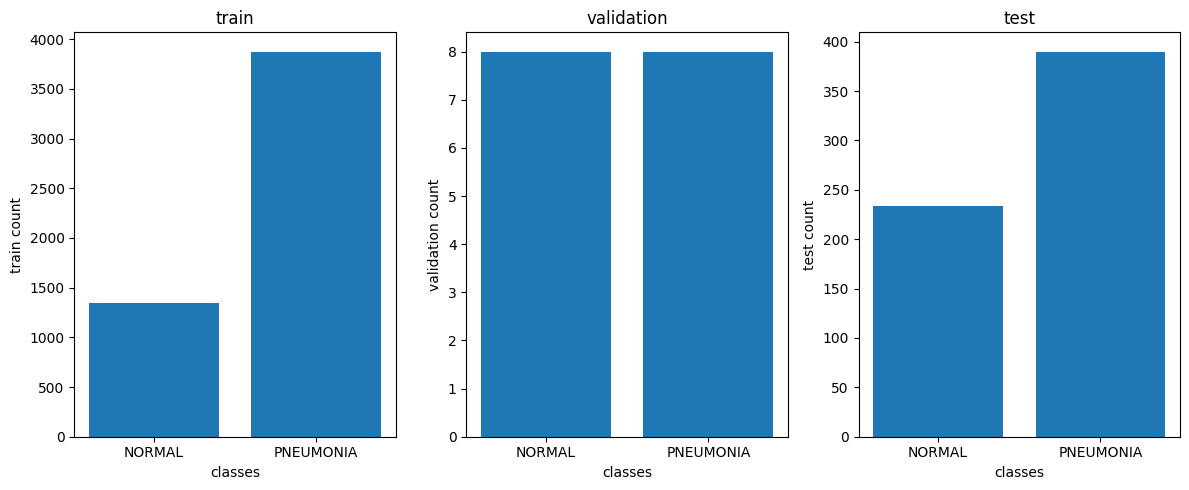

In [7]:

countes =  {
    "train": [len(train_image["normal"]), len(train_image["pneumonia"])],
    "validation": [len(val_image["normal"]), len(val_image["pneumonia"])],
    "test": [len(test_image["normal"]), len(test_image["pneumonia"])]
}

charts(countes)

## Identifier les éventuels problèmes

In [8]:
def check_image(img_path):
    try:
        with Image.open(img_path) as img:
            img.verify()
        return True    
    except:
        return False

In [ ]:

# train_error = {
#     cls: [img for img in train_image[cls] if not check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

# val_error = {
#     cls: [img for img in val_image[cls] if not check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

# test_error = {
#     cls: [img for img in test_image[cls] if not check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

In [10]:

train_valid = {
    cls: [img for img in train_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}

val_valid = {
    cls: [img for img in val_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}

test_valid = {
    cls: [img for img in test_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}



## Redimensionner les images et convertir au format RGB

In [33]:
def resize_images(img):
    image = load_img(
        img,
        target_size=(180, 180),
        color_mode="rgb"
    )
    return image
    

In [45]:
train_redim = {
    cls: np.array([
        resize_images(path)
        for path in train_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

val_redim = {
    cls: np.array([
        resize_images(path)
        for path in val_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

test_redim = {
    cls: np.array([
        resize_images(path)
        for path in test_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

## Préparer les images au format attendu par le modèle CNN

In [ ]:

from tensorflow.keras.utils import img_to_array

train_processed = {
    cls: np.array([
        img_to_array(path)
        for path in train_redim[cls]
    ], dtype=np.float32)
    for cls in ["normal", "pneumonia"]
}


val_processed = {
    cls: np.array([
        img_to_array(path)
        for path in val_redim[cls]
    ], dtype=np.float32)
    for cls in ["normal", "pneumonia"]
}

test_processed = {
    cls: np.array([
        img_to_array(path)
        for path in test_redim[cls]
    ], dtype=np.float32)
    for cls in ["normal", "pneumonia"]
}

## Associer les labels aux images

In [61]:
train_data_images = np.concatenate(
    (
        train_processed["normal"],
        train_processed["pneumonia"]
    ),
    axis=0
)
train_data_labels = np.concatenate((np.zeros(len(train_processed["normal"])), np.ones(len( train_processed["pneumonia"]))), axis= 0)
# ###########################
val_data_images = np.concatenate((val_processed["normal"], val_processed["pneumonia"]), axis=0)
val_data_labels = np.concatenate((np.zeros(len(val_processed["normal"])), np.ones(len( val_processed["pneumonia"]))), axis= 0)
# ###########################
test_data_images = np.concatenate((test_processed["normal"], test_processed["pneumonia"]), axis=0)
test_data_labels = np.concatenate((np.zeros(len(test_processed["normal"])), np.ones(len( test_processed["pneumonia"]))), axis=0)
# ###########################

## Normaliser les valeurs

In [65]:
train_norm_data = [d/ 255 for d in train_data_images]
val_norm_data = [d/ 255 for d in val_data_images]
test_norm_data = [d/ 255 for d in test_data_images]

## Visualiser un échantillon d'images

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for i in range(3):
    axes[0, i].imshow(train_redim["normal"][i].astype("uint8"))
    axes[0, i].set_title("normal")
    axes[0, i].axis("off")

    axes[1, i].imshow(train_redim["pneumonia"][i].astype("uint8"))
    axes[1, i].set_title("pneumonia")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## Étudier le déséquilibre

In [67]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_data_labels)


weights = compute_class_weight(class_weight="balanced", classes=classes, y = train_data_labels)

class_weights = dict(zip(classes, weights))

print(class_weights)


{np.float64(0.0): np.float64(1.9448173005219984), np.float64(1.0): np.float64(0.6730322580645162)}
